# RefEdit-Bench Mixed Prompt Agent Evaluation

Runs the MMEdit agent on RefEdit-Bench annotations using the mixed-modality instruction. The instruction preview names the exact selected visual prompt variable, for example `Remove <point_0>`, matching the object bound in the agent namespace. The benchmark has no target image reference; this notebook loads the source image and local object/reference geometry, then saves edited outputs, trajectories, raw agent steps, and timings for qualitative review. It runs all 200 samples by default; set `SAMPLE_LIMIT = 1` in the run cell for a quick smoke test. Set `RESUME_LAST_RUN = True` to continue the latest run, skipping completed samples and retrying failed ones. Set `RERUN_SPATIAL_SELECTOR_ISSUES = True` to detect and rerun only completed samples where spatial placement used a point/scribble despite a full annotation box.

Install with `uv sync --extra models --extra benchmark`. This notebook loads `refedit_bench_mixed.jsonl` from the latest `.out/annotation/refedit_bench/run_*/` by default. Set `MMEDIT_REFEDIT_BENCH_ANNOTATION_RUN=run_<timestamp>` to choose a run, or `MMEDIT_REFEDIT_BENCH_ANNOTATIONS` to provide an explicit JSONL path. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`. Start with a few annotation indices, inspect outputs and trajectories, then expand. HF image references use original split row indices.

Results are saved under `.out/evaluation/refedit_bench/mixed/run_<timestamp>/`.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from PIL import Image
from evaluation.notebook import create_run_directory, load_benchmark
from evaluation.common import annotate_sample, load_sample, run_benchmark, select_reference_prompts

BENCHMARK = "refedit_bench"
PROMPT_MODE = "mixed"
context = load_benchmark(BENCHMARK, prompt_mode=PROMPT_MODE)
ANNOTATION_FILE = context.annotation_file
OUTPUT_ROOT = context.output_dir
records = context.records
image_loader = context.image_loader
print(f"{len(records)} RefEdit-Bench annotations loaded from {ANNOTATION_FILE}")
print("Fields:", sorted(records[0]))

/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


200 RefEdit-Bench annotations loaded from /Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.out/annotation/refedit_bench/run_20261022_000000_000000/refedit_bench_mixed.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


easy:000 Change the color of <scribble_0> to white.
Reference selectors: [{'token': '<scribble_0>', 'variable': 'scribble_0', 'refers_to': 'the boat with bicycles and people', 'box': [40, 218, 365, 299], 'point': [87.5, 263.5], 'scribble': True}]


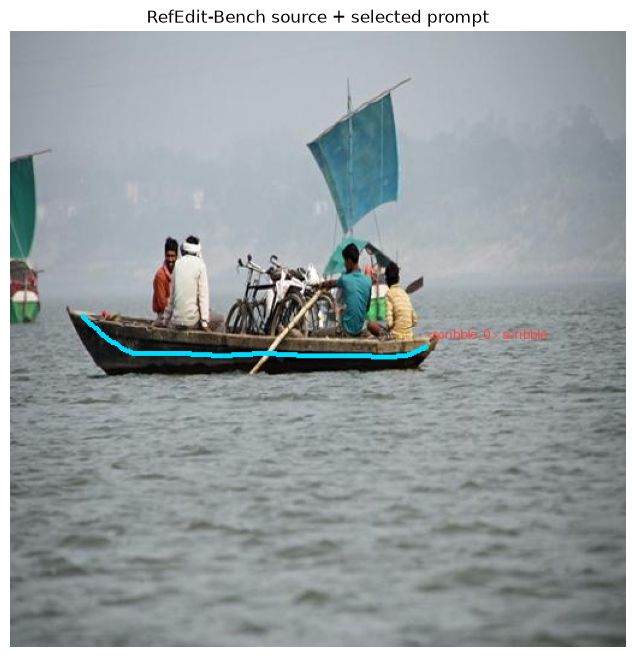

In [2]:
SAMPLE_INDEX = 0
record = records[SAMPLE_INDEX]
sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader, prompt_mode=PROMPT_MODE)
if not sample['instruction']:
    raise ValueError('RefEdit-Bench record has no instruction/prompt/edit_instruction/task field.')
select_reference_prompts(sample)
print(sample['sample_id'], sample['instruction'])
print('Reference selectors:', [{'token': r['display_token'], 'variable': (r.get('selected_prompt') or {}).get('variable'), 'refers_to': r['span'], 'box': r['bbox_xyxy'], 'point': r['point_xy'], 'scribble': bool(r['scribble_strokes'])} for r in sample['references']])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(annotate_sample(sample)); ax.set_title('RefEdit-Bench source + selected prompt')
ax.axis('off'); plt.show()

In [3]:
from framework.tools import image_editing_tools
from evaluation.notebook import create_agent_model

llm = create_agent_model()
tools = image_editing_tools()
print("RefEdit-Bench agent ready:", llm.model_id)

/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Loading pipeline components...: 100%|██████████| 5/5 [00:07<00:00,  1.50s/it]
There are modules in Flux2Transformer2DModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKLFlux2 that should be kept in float32: []. Casting directly wi

RefEdit-Bench agent ready: gemini-3.5-flash


In [4]:
SAMPLE_LIMIT = None  # Set to a positive number (e.g. 1) for a smoke test.
if SAMPLE_LIMIT is not None and SAMPLE_LIMIT < 1:
    raise ValueError('SAMPLE_LIMIT must be positive or None.')
SAMPLE_COUNT = len(records) if SAMPLE_LIMIT is None else min(SAMPLE_LIMIT, len(records))
from evaluation.notebook import resolve_run_directory
from evaluation.spatial_selector_issues import find_spatial_selector_issues
RESUME_LAST_RUN = True  # True continues the latest run and skips completed samples.
SAMPLE_INDICES = [1]
RUN_DIR = resolve_run_directory(OUTPUT_ROOT) if RESUME_LAST_RUN else create_run_directory(OUTPUT_ROOT)
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    prompt_mode=PROMPT_MODE,
    output_dir=RUN_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    resume=RESUME_LAST_RUN,
    rerun_completed=True,
    display_fn=None,
)
print('Run directory:', RUN_DIR)
print(f'Processed {len(benchmark_results)} of {SAMPLE_COUNT} RefEdit-Bench samples.')
print('RefEdit-Bench has no target image; evaluate the saved outputs against the benchmark protocol.')

refedit_bench inference:   0%|          | 0/1 [00:00<?, ?sample/s, sample=easy:001, status=running]/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/peft/tuners/tuners_utils.py:1049: RuntimeWarning: While injecting the PEFT adapters, an inconsistency was discovered between the PEFT config and the provided state_dict. This is not necessarily an issue and can be ignored if this was the intent. The PEFT config contained these additional target modules: ['transformer_blocks.0.attn.to_k', 'transformer_blocks.0.attn.to_out.0', 'transformer_blocks.0.attn.to_q', 'transformer_blocks.0.attn.to_v', 'transformer_blocks.1.attn.to_k', 'transformer_blocks.1.attn.to_out.0', 'transformer_blocks.1.attn.to_q', 'transformer_blocks.1.attn.to_v', 'transformer_blocks.2.attn.to_k', 'transformer_blocks.2.attn.to_out.0', 'transformer_blocks.2.attn.to_q', 'transformer_blocks.2.attn.to_v', 'transformer_blocks.3.attn.to_k', 'transformer_blocks.3.attn.to_out.0', 'transformer_blocks.

Run directory: /Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.out/evaluation/refedit_bench/mixed/run_20261022_165957_019114
Processed 1 of 200 RefEdit-Bench samples.
RefEdit-Bench has no target image; evaluate the saved outputs against the benchmark protocol.


In [5]:
completed = [r for r in benchmark_results if r['status'] == 'completed']
failed = [r for r in benchmark_results if r['status'] == 'failed']
print(f'RefEdit-Bench samples: {len(benchmark_results)} | completed: {len(completed)} | failed: {len(failed)}')
if benchmark_results: print(f"Mean runtime: {sum(r['elapsed_seconds'] for r in benchmark_results)/len(benchmark_results):.2f}s")
print('Review saved output images and trajectories; runtime/status are not image-quality scores.')

RefEdit-Bench samples: 1 | completed: 1 | failed: 0
Mean runtime: 19.30s
Review saved output images and trajectories; runtime/status are not image-quality scores.
